# Analyse Exploratoire des Données

Dans cette partie, nous chercherons à comprendre les données avant de construire un modèle capable de prédire `responder_6`. L'étude porte pour l'instant sur un seul fichier, `part-0.parquet`. Les conclusions ne seront donc pas automatiquement étendues aux autres partitions.

Nous allons d'abord présenter le sens des colonnes, puis nous vérifirons la structure du fichier. Nous examinerons ensuite les valeurs manquantes, la distribution de la variable cible et ses différences selon les jours et les instruments. La dernière partie portera sur les poids utilisés dans l'évaluation.

## 1. Présentation des données

### 1.1. Source des fichiers

Nous utiliserons le fichier `train.parquet/partition_id=0/part-0.parquet`, téléchargé depuis le dépôt `TnnnT0326/Jane_Street_Competition` sur Hugging Face. Ce dépôt est une copie des données associées à la compétition Jane Street Real-Time Market Data Forecasting, publiée par un tiers.

Sources :
- [Dépôt Hugging Face utilisé](https://huggingface.co/datasets/TnnnT0326/Jane_Street_Competition)
- [Fichier de la partition 0](https://huggingface.co/datasets/TnnnT0326/Jane_Street_Competition/blob/main/train.parquet/partition_id%3D0/part-0.parquet)
- [Description officielle des données — Kaggle](https://www.kaggle.com/competitions/jane-street-real-time-market-data-forecasting/data)

### 1.2. Présentation des variables

D'après la documentation officielle, une ligne décrit un instrument à un instant donné, et est identifiable par 3 identifiants :

| Colonne | Rôle | Exemple |
|---|---|---|
| `date_id` | Jour, dans l'ordre chronologique (les dates réelles sont masquées) | `0` est le premier jour dans notre partition |
| `time_id` | Position temporelle à l'intérieur du jour | Deux lignes de même `date_id` et `time_id` concernent le même instant |
| `symbol_id` | Instrument financier anonymisé | `1` et `7` désignent deux instruments différents |

Un même `symbol_id` répété sur plusieurs lignes permet de suivre le même instrument au cours du temps. Cependant, son nom et sa nature économique ne sont pas accessibles à partir de cet identifiant. 

Rôles des autres variables :
- `feature_00` à `feature_78` : variables de marché anonymisées 
- `responder_0` à `responder_8` : réponses anonymisées
- `responder_6` : variable cible de notre projet
- `weight` : poids

Source : [description officielle du dataset](https://www.kaggle.com/competitions/jane-street-real-time-market-data-forecasting/data).

## 2. Lecture du fichier

### 2.1. Chargement du Dataset

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

In [31]:
# Chemin du fichier
data_path = "/Users/fayssal_meharzi/Documents/Machine Learning M2/JaneStreetProject/DataSet/part-0.parquet"

# Charge les données dans un tableau
df = pd.read_parquet(data_path)

# Affiche les dimensions et les noms des colonnes
print("Nombre de lignes :", df.shape[0])
print("Nombre de colonnes :", df.shape[1])
print("Noms des colonnes :", df.columns.tolist())

Nombre de lignes : 1944210
Nombre de colonnes : 92
Noms des colonnes : ['date_id', 'time_id', 'symbol_id', 'weight', 'feature_00', 'feature_01', 'feature_02', 'feature_03', 'feature_04', 'feature_05', 'feature_06', 'feature_07', 'feature_08', 'feature_09', 'feature_10', 'feature_11', 'feature_12', 'feature_13', 'feature_14', 'feature_15', 'feature_16', 'feature_17', 'feature_18', 'feature_19', 'feature_20', 'feature_21', 'feature_22', 'feature_23', 'feature_24', 'feature_25', 'feature_26', 'feature_27', 'feature_28', 'feature_29', 'feature_30', 'feature_31', 'feature_32', 'feature_33', 'feature_34', 'feature_35', 'feature_36', 'feature_37', 'feature_38', 'feature_39', 'feature_40', 'feature_41', 'feature_42', 'feature_43', 'feature_44', 'feature_45', 'feature_46', 'feature_47', 'feature_48', 'feature_49', 'feature_50', 'feature_51', 'feature_52', 'feature_53', 'feature_54', 'feature_55', 'feature_56', 'feature_57', 'feature_58', 'feature_59', 'feature_60', 'feature_61', 'feature_62', '

La partition 0 contient **1 944 210 lignes et 92 colonnes**, dont trois identifiants, un poids, 79 variables explicatives et neuf réponses.

In [51]:
# Affiche les cinq premières lignes
df.head()

,date_id,time_id,symbol_id,weight,feature_00,feature_01,feature_02,feature_03,feature_04,feature_05,...,feature_78,responder_0,responder_1,responder_2,responder_3,responder_4,responder_5,responder_6,responder_7,responder_8
0,0,0,1,3.889038,NaN,NaN,NaN,NaN,NaN,0.851033,...,-0.281498,0.738489,-0.069556,1.380875,2.005353,0.186018,1.218368,0.775981,0.346999,0.095504
1,0,0,7,1.370613,NaN,NaN,NaN,NaN,NaN,0.676961,...,-0.302441,2.965889,1.190077,-0.523998,3.849921,2.626981,5.000000,0.703665,0.216683,0.778639
2,0,0,9,2.285698,NaN,NaN,NaN,NaN,NaN,1.056285,...,-0.096792,-0.864488,-0.280303,-0.326697,0.375781,1.271291,0.099793,2.109352,0.670881,0.772828
3,0,0,10,0.690606,NaN,NaN,NaN,NaN,NaN,1.139366,...,-0.296244,0.408499,0.223992,2.294888,1.097444,1.225872,1.225376,1.114137,0.775199,-1.379516
4,0,0,14,0.440570,NaN,NaN,NaN,NaN,NaN,0.955200,...,3.418133,-0.373387,-0.502764,-0.348021,-3.928148,-1.591366,-5.000000,-3.572820,-1.089123,-5.000000


Les `NaN` désignent des valeurs manquantes et non une erreur de lecture. Plusieurs variables sont absentes ici, mais nous vérifierons plus loin si cette absence concerne aussi le reste du fichier.

### 2.2. Types des variables

In [34]:
# Affiche le type de chaque colonne
df.dtypes

date_id          int16
time_id          int16
symbol_id         int8
weight         float32
feature_00     float32
                ...   
responder_4    float32
responder_5    float32
responder_6    float32
responder_7    float32
responder_8    float32
Length: 92, dtype: object

### 2.3. Période et nombre d'instruments

In [35]:
# Sélectionne les colonnes d'identification
identifiants = df[["date_id", "symbol_id", "time_id"]]

print("Nombre de lignes :", len(identifiants))
print("Nombre de jours distincts :", identifiants["date_id"].nunique())
print("Premier jour :", identifiants["date_id"].min())
print("Dernier jour :", identifiants["date_id"].max())
print("Nombre d'instruments distincts :", identifiants["symbol_id"].nunique())

Nombre de lignes : 1944210
Nombre de jours distincts : 170
Premier jour : 0
Dernier jour : 169
Nombre d'instruments distincts : 20


La `partition 0` couvre **170 jours, de 0 à 169, et 20 instruments**.

### 2.4. Nombre d'observations et vérification de l'unicité des clés

Compter les lignes ne permet pas de savoir si un même instant apparaît plusieurs fois pour un instrument au cours d’une journée. Nous allons donc aussi compter les `time_id` pour vérifier que chaque ligne correspond bien à un instant différent.

In [36]:
# Regroupe les observations par jour et par instrument
groupes = identifiants.groupby(["date_id", "symbol_id"])

# Compte les lignes dans chaque groupe
observations_par_jour_instrument = groupes.size()
observations_par_jour_instrument.describe()

count    2290.0
mean      849.0
std         0.0
min       849.0
25%       849.0
50%       849.0
75%       849.0
max       849.0
dtype: float64

In [37]:
# Compte les valeurs manquantes dans chaque colonne d'identification
print("Valeurs manquantes par colonne :")
print(identifiants.isna().sum())

# Vérifie si un même triplet (jour, instrument, instant) apparaît plusieurs fois
print("Nombre de clés dupliquées :", identifiants.duplicated().sum())

# Compte les instants différents dans chaque groupe
instants_par_couple = groupes["time_id"].nunique()
print("Minimum d'instants distincts :", instants_par_couple.min())
print("Maximum d'instants distincts :", instants_par_couple.max())

Valeurs manquantes par colonne :
date_id      0
symbol_id    0
time_id      0
dtype: int64
Nombre de clés dupliquées : 0
Minimum d'instants distincts : 849
Maximum d'instants distincts : 849


Les **2 290 couples `(jour, instrument)`** comptent chacun **849 lignes et 849 instants distincts**. Le nombre total est cohérent puisque, 2 290 × 849 = 1 944 210. De plus, aucun triplet `(date_id, symbol_id, time_id)` n'est dupliqué et les identifiants ne contiennent pas de valeur manquante.

Ces résultats confirment l'unicité des observations.

## 3. Valeurs manquantes

L'aperçu du début montrait plusieurs colonnes absentes. Mais sont elles entièrement vides sur l'ensemble la partition ?

In [38]:
# Compte les valeurs manquantes et les valeurs présentes
nombre_manquants = df.isna().sum()
nombre_presents = df.count()

# Calcule le pourcentage de valeurs manquantes
taux_manquants = nombre_manquants / len(df) * 100

# Regroupe les résultats dans un tableau
resume_manquants = pd.DataFrame({"Valeurs manquantes (%)": taux_manquants,"Nombre de valeurs présentes": nombre_presents})

# Affiche les colonnes entièrement vides
colonnes_vides = resume_manquants[nombre_presents == 0]
colonnes_vides

,Valeurs manquantes (%),Nombre de valeurs présentes
feature_00,100.0,0
feature_01,100.0,0
feature_02,100.0,0
feature_03,100.0,0
feature_04,100.0,0
feature_21,100.0,0
feature_26,100.0,0
feature_27,100.0,0
feature_31,100.0,0


Le comptage confirme l'absence de valeur dans `feature_00`, `feature_01`, `feature_02`, `feature_03`, `feature_04`, `feature_21`, `feature_26`, `feature_27` et `feature_31` sur cette partition.

Pour un modèle entraîné uniquement sur ce fichier, ces colonnes ne permettraient pas d'apprendre une relation avec la cible. Leur exclusion sera donc décidée après le découpage, à partir du seul entraînement. Nous conservons donc pour l'instant le fichier brut car ces variables pourraient être renseignées dans d'autres partitions.

Une colonne partiellement manquante peut en revanche rester utile. Il faudra examiner les absences selon les jours et les instruments avant de choisir un traitement. Aucun seuil de suppression n'est fixé ici.


**Bilan.** Nous avons 9 colonnes vides sur tout le fichier mais l'analyse complète et les choix de préparation seront faits sur la période d'entraînement dans le notebook suivant.

## 4. Distribution de la variable cible

Nous allons maintenant étudier la variable  `responder_6` sur l'ensemble de la partition. 

### 4.1. Statistiques descriptives

In [40]:
# Sélectionner la variable à prédire
cible = df["responder_6"].astype("float64")

# Compter les valeurs manquantes
print("Valeurs manquantes :", cible.isna().sum())

# Afficher les statistiques descriptives
display(cible.describe())

Valeurs manquantes : 0


count    1.944210e+06
mean     1.487633e-03
std      8.705768e-01
min     -5.000000e+00
25%     -3.558709e-01
50%     -9.597129e-03
75%      3.360999e-01
max      5.000000e+00
Name: responder_6, dtype: float64

Les **1 944 210 valeurs** de la cible sont renseignées

|  | Valeur approximative | Interprétation |
|---|---:|---|
| Moyenne | 0,00149 | La moyenne de responder_6 sur l’ensemble du fichier est proche de zéro |
| Écart-type | 0,871 | Dispersion autour de la moyenne |
| Minimum / maximum | −5 / +5 | Extrêmes observés après écrêtage |
| Médiane | −0,00960 | Valeur séparant les deux moitiés des observations |
| Premier / troisième quartile | −0,356 / +0,336 | La moitié des observations ont une valeur de responder_6 comprise entre −0,356 et +0,336 |

Une moyenne proche de zéro ne signifie pas que toutes les valeurs sont faibles : les valeurs positives et négatives peuvent se compenser. Elle ne démontre pas non plus que la cible est imprévisible.

### 4.2. Histogramme et comparaison à une loi normale

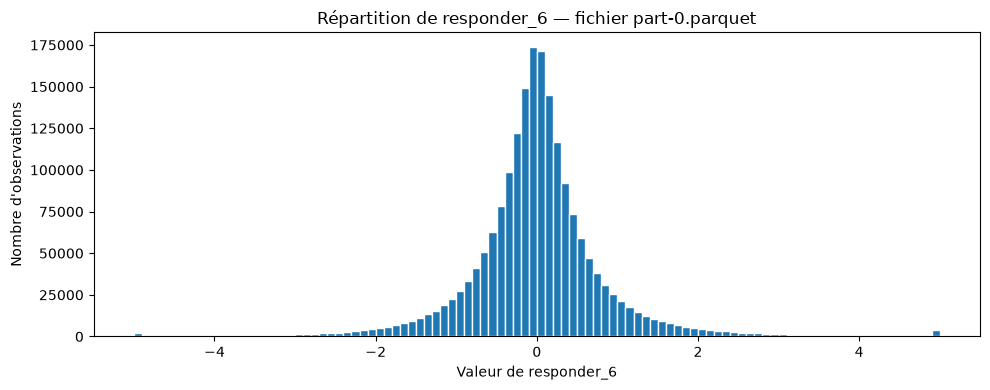

In [ ]:
plt.figure(figsize=(10, 4))
plt.hist(cible, bins=100, edgecolor="white")
plt.xlabel("Valeur de responder_6")
plt.ylabel("Nombre d'observations")
plt.title("Répartition de responder_6 — fichier part-0.parquet")
plt.tight_layout()
plt.show()

La symétrie approximative ne suffit pas à conclure qu'il s'agit d'une loi normale. Nous allons donc superposer une densité normale ayant la même moyenne et le même écart-type que la variable cible. Avec `density=True`, l'aire de l'histogramme vaut 1, ce qui permettra de comparer les deux formes sur la même échelle.

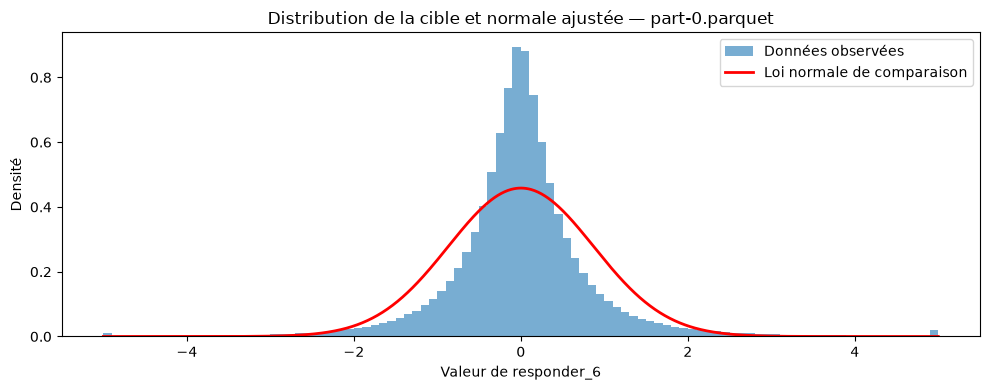

In [41]:
moyenne = cible.mean()
ecart_type = cible.std()
x = np.linspace(-5, 5, 1000)

plt.figure(figsize=(10, 4))
plt.hist(cible, bins=100, density=True, alpha=0.6,label="Données observées")
plt.plot(x, norm.pdf(x, loc=moyenne, scale=ecart_type),color="red", linewidth=2, label="Loi normale de comparaison")
plt.xlabel("Valeur de responder_6")
plt.ylabel("Densité")
plt.title("Distribution de la cible et normale ajustée — part-0.parquet")
plt.legend()
plt.tight_layout()
plt.show()

La courbe rouge ne suit pas vraiment la forme de l’histogramme. Nos données contiennent davantage de valeurs proches de zéro, et moins de valeurs autour de −1 et de +1 que la loi normale utilisée pour la comparaison. On retrouve aussi les petites barres à −5 et +5, liées à l’écrêtage, que la courbe rouge ne représente pas.

La normalité de la variable cible n'est pas une condition pour utiliser Ridge ou un modèle d'arbres, qu'il s'agisse d'une forêt aléatoire ou d'un Gradient Boosting.

### 4.3. Observations aux bornes

In [ ]:
for borne in [-5, 5]:
    nombre = (cible == borne).sum()
    pourcentage = nombre / len(cible) * 100
    print(f"Valeur {borne} : {nombre:,} observations ({pourcentage:.3f} %)")

Valeur -5 : 1,921 observations (0.099 %)
Valeur 5 : 3,515 observations (0.181 %)


Il y a **1 921 valeurs valant −5** et **3 515 valant +5**, soit **5 436 observations** et environ **0,28 % du fichier**. La documentation précise que les responders sont écrêtés à ces bornes, les petites barres observées sur l'histogramme sont donc cohérentes.

Nous conserverons ces observations. Cependant, leur position aux bornes ne suffit pas à les qualifier d'erreurs, et nous ne connaissons pas leurs valeurs avant l'écrêtage.

**Bilan.** La variable cible est entièrement renseignée et centrée autour de zéro, avec une distribution qui diffère d'une normale.

## 5. Analyse de responder_6 par jour et par instrument

Jusqu’ici, nous avons calculé la moyenne et l’écart-type de `responder_6` sur l’ensemble du fichier.

Nous allons maintenant refaire ces calculs pour chaque jour, en regroupant tous les instruments présents ce jour-là. Cela permettra de comparer les journées entre elles. Par exemple : La moyenne est-elle différente au jour 1 et au jour 2 ? Les valeurs sont-elles plus dispersées certains jours que d’autres ?

Puis, pour chaque instrument, nous calculerons la moyenne et l’écart-type de `responder_6` à partir de toutes les lignes du fichier correspondant à cet instrument. Nous pourrons ainsi comparer la moyenne et la dispersion de `responder_6` entre instruments. Il faudra toutefois tenir compte du fait qu’ils ne sont pas tous observés sur les mêmes jours.

### 5.1. Moyenne de responder_6 par jour

Chaque point du graphique est la moyenne de toutes les valeurs de `responder_6` d'un jour, tout instruments et instants confondus.

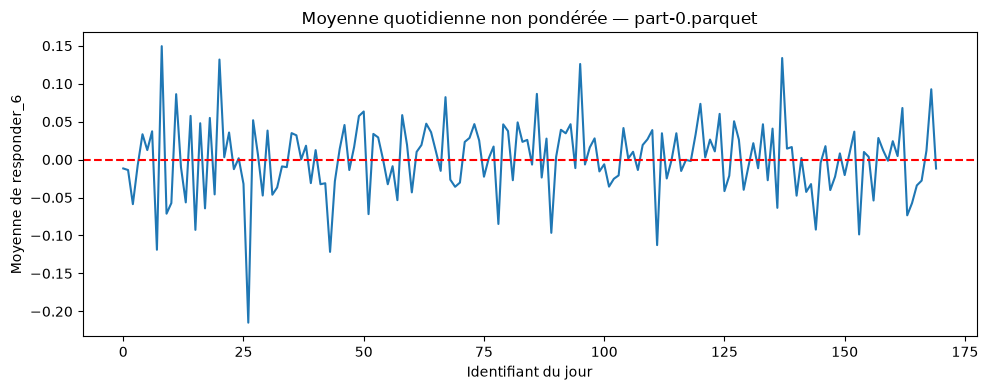

In [ ]:
moyenne_par_jour = cible.groupby(identifiants["date_id"]).mean()

moyenne_par_jour.plot(figsize=(10, 4))
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Identifiant du jour")
plt.ylabel("Moyenne de responder_6")
plt.title("Moyenne quotidienne non pondérée — part-0.parquet")
plt.tight_layout()
plt.show()

Ce graphique montre que la moyenne de `responder_6` varie d’un jour à l’autre. Il ne suffit toutefois pas à savoir si ces variations se répètent de façon prévisible ou si la moyenne change durablement au cours du temps. De plus, comme nous ne connaissons pas la définition économique précise de `responder_6`, une moyenne positive ne signifie pas nécessairement que les prix ont augmenté ce jour-là, et une moyenne négative ne signifie pas nécessairement qu’ils ont baissé.

### 5.2. Dispersion de responder_6 par jour

Deux journées peuvent avoir des moyennes proches mais des valeurs plus ou moins dispersées. Nous allons ici calculer l'écart-type autour de la moyenne de chaque jour, toujours sans pondération.

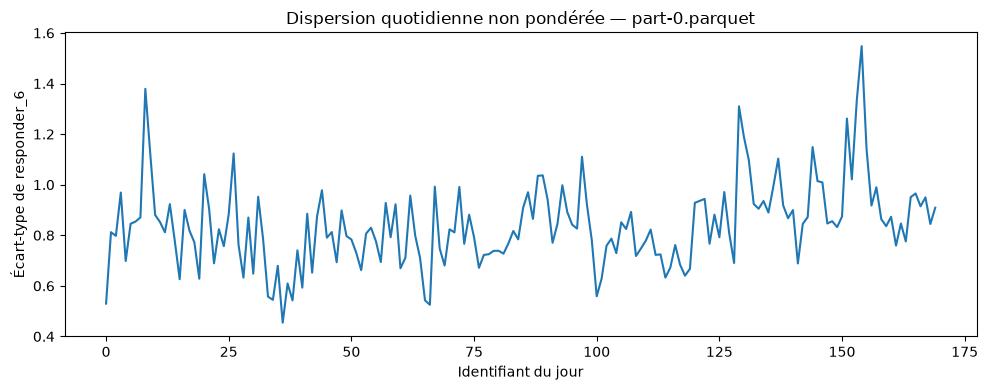

In [ ]:
dispersion_par_jour = cible.groupby(identifiants["date_id"]).std()

dispersion_par_jour.plot(figsize=(10, 4))
plt.xlabel("Identifiant du jour")
plt.ylabel("Écart-type de responder_6")
plt.title("Dispersion quotidienne non pondérée — part-0.parquet")
plt.tight_layout()
plt.show()

L’écart-type de `responder_6` vaut environ 0,45 au jour 36 et 1,55 au jour 154. Cela signifie que les valeurs du jour 36 sont davantage regroupées autour de leur moyenne, tandis que celles du jour 154 sont plus dispersées autour de la leur.

Pour chaque jour, le calcul utilise toutes les observations de tous les instruments présents. Les écarts peuvent donc venir à la fois des différences entre instruments et des variations de `responder_6` au cours de la journée pour un même instrument.

De plus, les instruments présents ne sont pas forcément les mêmes d’un jour à l’autre. Cela peut aussi expliquer une partie des différences entre les écarts-types quotidiens. Ce graphique ne permet donc pas de conclure qu’un instrument particulier est devenu plus volatil, d’autant que `responder_6` ne représente pas directement un rendement connu.

Le tableau suivant réunit le nombre d'observation, la moyenne et l'écart-type des dix premiers jours.

In [42]:
resume_par_jour = cible.groupby(identifiants["date_id"]).agg(nombre_observations="count", moyenne="mean",ecart_type="std")
display(resume_par_jour.head(10))

,nombre_observations,moyenne,ecart_type
date_id,,,
0,6792,-0.011707,0.529894
1,10188,-0.013778,0.812211
2,9339,-0.058745,0.797652
3,10188,-0.007691,0.968893
4,10188,0.033380,0.698249
5,7641,0.012517,0.845340
6,10188,0.037249,0.854173
7,6792,-0.118852,0.870583
8,8490,0.149477,1.379004


Chaque ligne du tableau correspond à une journée. Elle indique le nombre d’observations disponibles, ainsi que la moyenne et l’écart-type de `responder_6` pour cette journée, tous instruments présents confondus.

Par exemple, au jour 8, les 8490 valeurs de `responder_6` ont une moyenne d’environ 0,149 et un écart-type de 1,379. Au jour 0, la moyenne est d’environ −0,012 et l’écart-type de 0,530. Les valeurs sont donc moins dispersées autour de leur moyenne qu’au jour 8.

Le nombre d’observations varie aussi selon les jours. Comme chaque instrument présent possède 849 observations par jour, les 6792 lignes du jour 0 correspondent à 8 instruments, contre 12 instruments pour les 10188 lignes du jour 1.

### 5.3. Moyenne et dispersion de responder_6 par instrument

Après avoir comparé les journées, nous allons comparer les instruments. Pour chaque `symbol_id`, nous calculons le nombre d’observations, la moyenne et l’écart-type de `responder_6`, en utilisant toutes les lignes correspondant à cet instrument dans le fichier.

Chaque ligne du tableau résume donc un instrument sur l’ensemble des jours où il est présent. Nous pourrons ainsi voir si certains instruments ont une moyenne plus élevée que d’autres et si leurs valeurs de `responder_6` sont plus ou moins dispersées autour de leur moyenne.

In [43]:
resume_par_instrument = cible.groupby(identifiants["symbol_id"]).agg(nombre_observations="count",moyenne="mean",ecart_type="std")
display(resume_par_instrument)

,nombre_observations,moyenne,ecart_type
symbol_id,,,
0,138387,-0.006660,0.672173
1,143481,-0.000238,0.635928
2,73863,0.025076,0.870379
3,60279,0.036099,1.080854
7,140934,0.002074,0.873424
8,108672,0.003363,0.897744
9,138387,0.007991,0.718917
10,102729,-0.006760,0.808609
11,58581,-0.034786,1.162085


Le nombre d’observations varie selon les instruments, nous disposons par exemple, de 141783 lignes pour l’instrument 16, contre 20376 pour l’instrument 30.

Pour chacun des 20 instruments, la moyenne de `responder_6` est proche de zéro. En revanche, les valeurs sont plus ou moins dispersées autour de cette moyenne. Par exemple, l’écart-type est d’environ 0,636 pour l’instrument 1, contre 1,323 pour l’instrument 30. Les valeurs de `responder_6` sont donc davantage regroupées autour de leur moyenne pour l’instrument 1 que pour l’instrument 30.

Cela ne signifie pas que les valeurs de l’instrument 1 seront plus faciles à prédire. Pour le savoir, il faudra vérifier si les variables explicatives permettent de prévoir les valeurs de `responder_6` sur des observations qui n’ont pas servi à entraîner le modèle.


Nous allons maintenant compter le nombre de jours où chaque instrument apparaît dans le fichier. Chacun d'eux possède 849 observations par jour de présence, mais tous ne sont pas présents sur autant de jours.

In [44]:
jours_par_instrument = (identifiants.groupby("symbol_id")["date_id"].nunique())
resume_par_instrument["nombre_jours"] = jours_par_instrument

display(resume_par_instrument)

,nombre_observations,moyenne,ecart_type,nombre_jours
symbol_id,,,,
0,138387,-0.006660,0.672173,163
1,143481,-0.000238,0.635928,169
2,73863,0.025076,0.870379,87
3,60279,0.036099,1.080854,71
7,140934,0.002074,0.873424,166
8,108672,0.003363,0.897744,128
9,138387,0.007991,0.718917,163
10,102729,-0.006760,0.808609,121
11,58581,-0.034786,1.162085,69


L’instrument 1 possède davantage d’observations que l’instrument 30 parce qu’il apparaît sur davantage de jours : 169 contre 24. Chaque instrument ayant exactement 849 observations par jour où il est présent, le nombre total de ses observations dépend directement de son nombre de jours de présence dans le fichier.

### Bilan 
Même si la moyenne de `responder_6` sur l’ensemble du fichier est proche de zéro, sa moyenne et son écart-type varient selon les jours et selon les instruments. Les instruments ne sont toutefois pas tous observés aux mêmes dates, les différences entre leurs statistiques peuvent donc aussi venir des journées sur lesquelles elles sont calculées.

Lorsque nous évaluerons les modèles, nous regarderons leurs résultats sur l’ensemble des données de validation, puis leurs erreurs par jour et par instrument. Cela permettra de vérifier si un modèle prédit correctement pour plusieurs journées et plusieurs instruments, ou si son résultat d’ensemble cache de mauvaises prédictions pour certains d’entre eux.

## 6. Rôle des poids

La colonne `weight` intervient dans le score. Nous vérifirons d'abord ses valeurs, puis nous comparons des moyennes simples et pondérées pour comprendre l'effet de ces poids dans notre partition.

### 6.1. Distribution des poids

In [45]:
# Sélectionne les poids
poids = df["weight"].astype("float64")

# Vérifie les valeurs manquantes, égales à zéro ou négatives
print("Poids manquants :", poids.isna().sum())
print("Poids égaux à zéro :", (poids == 0).sum())
print("Poids négatifs :", (poids < 0).sum())

# Affiche les statistiques descriptives
display(poids.describe())

Poids manquants : 0
Poids égaux à zéro : 0
Poids négatifs : 0


count    1.944210e+06
mean     1.973282e+00
std      9.691969e-01
min      4.405696e-01
25%      1.323803e+00
50%      1.763827e+00
75%      2.393846e+00
max      6.011999e+00
Name: weight, dtype: float64

Tous les poids sont renseignés et strictement positifs. Ils vont d'environ **0,441 à 6,012**, pour une moyenne de **1,973**. Ces poids ne sont ni des probabilités ni des pourcentages, ils servent seulement à donner plus d’importance à certaines observations dans le calcul du score du modèle. Cependant, les informations dont nous disposons ne permettent pas de savoir comment ces poids ont été calculés ni pourquoi certaines observations ont un poids plus élevé que d’autres.

### 6.2. Moyennes globale simple et pondérée

Pour des observations $y_i$ et des poids $w_i$, la moyenne pondérée est :

$$\bar y_w = \frac{\sum_i w_i y_i}{\sum_i w_i}.$$

Contrairement à la moyenne simple, elle donne davantage d'influence aux observations dont le poids est élevé. Il s'agit ici d'une statistique descriptive, pas du score de prédiction.

In [ ]:
moyenne_simple = cible.mean()
moyenne_ponderee = (poids * cible).sum() / poids.sum()

print("Moyenne simple :", moyenne_simple)
print("Moyenne pondérée :", moyenne_ponderee)

Moyenne simple : 0.001487633236726828
Moyenne pondérée : 0.0015630033334547674


Nous observons des résultats relativement proches, **0,001488** pour la moyenne simple et **0,001563** pour la moyenne pondérée. La pondération modifie donc peu la moyenne globale de cette partition.

Cela ne signifie pas que les poids auront peu d'effet sur l'évaluation des modèles : ils modifieront aussi la contribution des erreurs de prédiction. La proximité des moyennes globales peut en outre masquer des écarts à l'échelle quotidienne.

### 6.3. Comparaison jour par jour

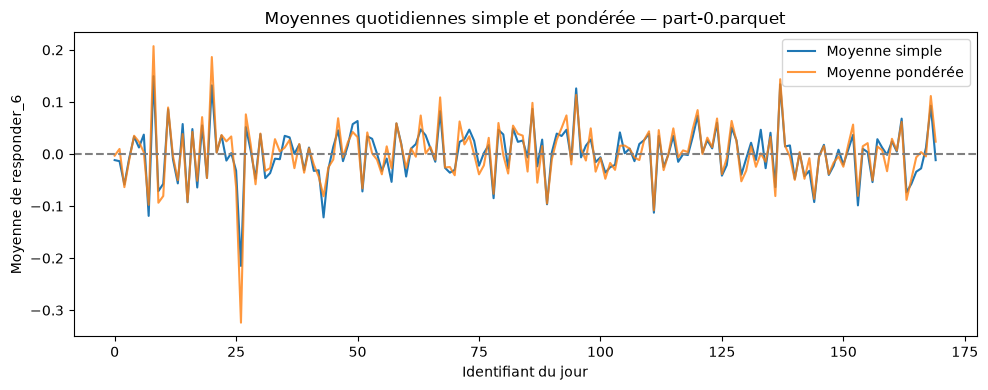

In [47]:
jours = identifiants["date_id"]

# Moyenne simple de responder_6 pour chaque jour
moyenne_par_jour = cible.groupby(jours).mean()

# Moyenne de responder_6 tenant compte des poids pour chaque jour
moyenne_ponderee_par_jour = ((poids * cible).groupby(jours).sum()/ poids.groupby(jours).sum())

plt.figure(figsize=(10, 4))
plt.plot(moyenne_par_jour, label="Moyenne simple")
plt.plot(moyenne_ponderee_par_jour, label="Moyenne pondérée", alpha=0.8)
plt.axhline(0, color="gray", linestyle="--")
plt.xlabel("Identifiant du jour")
plt.ylabel("Moyenne de responder_6")
plt.title("Moyennes quotidiennes simple et pondérée — part-0.parquet")
plt.legend()
plt.tight_layout()
plt.show()

La courbe bleue représente la moyenne de `responder_6` pour chaque jour, en donnant la même importance à chaque observation. La courbe orange représente la moyenne calculée avec les poids de la colonne `weight`, les observations ayant un poids élevé comptent davantage dans ce calcul.

Les deux courbes sont souvent proches, mais elles s’écartent pour certaines journées. Au jour 26, par exemple, la moyenne simple vaut environ −0,21, contre −0,32 pour la moyenne pondérée. Pour cette journée, tenir compte des poids donne donc une moyenne de `responder_6` plus négative.

**Bilan.** Sur l’ensemble du fichier, les moyennes simple et pondérée sont très proches. Cependant, cette comparaison par jour montre que les poids peuvent modifier davantage la moyenne de certaines journées. Pour évaluer nos modèles, nous utiliserons le même score tenant compte de `weight`, une même erreur de prédiction comptera davantage pour une observation dont le poids est élevé.

## 7. Conclusion

Cette première exploration des données nous a permis de mieux comprendre le fichier `part-0.parquet`. Il contient **1 944 210 observations et 92 colonnes**, réparties sur **170 jours et 20 instruments financiers**. Chaque instrument est observé à **849 instants distincts par jour où il est présent**, mais tous les instruments n’apparaissent pas chaque jour. Nous n’avons trouvé aucun doublon pour une même combinaison de `date_id`, `symbol_id`, `time_id`.

Nous avons ensuite calculé le nombre de valeurs manquantes sur l’ensemble du fichier et nous avons constaté que **Neuf variables sont entièrement vides** : `feature_00`, `feature_01`, `feature_02`, `feature_03`, `feature_04`, `feature_21`, `feature_26`, `feature_27` et `feature_31`. Ce constat concerne uniquement cette partition, car ces variables pourraient contenir des valeurs dans d’autres partitions. Leur traitement sera donc décidé lors de la préparation des données, à partir de la période d’entraînement.

La variable cible `responder_6` ne contient aucune valeur manquante. Sa moyenne sur l’ensemble du fichier est proche de zéro, mais sa distribution ne correspond pas à celle d’une loi normale ayant la même moyenne et le même écart-type. Nous avons également compté **5 436 valeurs égales à −5 ou +5**, soit environ **0,28 % des observations**. Ces deux valeurs correspondent aux limites appliquées à la variable cible. Les valeurs initialement inférieures à −5 sont ramenées à −5, et celles supérieures à +5 sont ramenées à +5. Les observations situées à ces limites ne sont donc pas, pour cette seule raison, des erreurs à supprimer.

Nous avons ensuite calculé la moyenne et l’écart-type de `responder_6` séparément pour chaque jour, en regroupant tous les instruments présents ce jour-là. Cette comparaison montre que la moyenne change d’une journée à l’autre et que les valeurs sont plus dispersées certains jours.

Nous avons aussi effectué ces calculs, mais cette fois ci, pour chaque instrument, en regroupant toutes ses observations dans le fichier. Les moyennes restent proches de zéro, mais les écarts-types diffèrent entre instruments. Ces différences doivent être interprétées avec précaution, car les instruments ne sont pas tous observés aux mêmes dates. Le nombre de leurs observations dépend directement du nombre de jours où ils sont présents, puisqu’ils comptent chacun 849 observations par journée de présence.

Enfin, la colonne `weight` ne contient aucune valeur manquante, nulle ou négative. Les moyennes simple et pondérée de `responder_6` sont très proches sur l’ensemble du fichier, mais elles diffèrent davantage certains jours. Ces poids donnent plus d’importance à certaines observations dans le calcul du score. Nous utiliserons donc le même score pondéré pour comparer tous les modèles.

### Limites de cette première étude

Nous avons travaillé sur une seule partition. Les résultats obtenus décrivent uniquement ce fichier, et ne permettent pas de savoir si les autres partitions présentent les mêmes caractéristiques.

Le fichier provient d’une copie publiée par un tiers sur Hugging Face. Nos vérifications permettent de contrôler son contenu, mais ne prouvent pas qu’il est identique au fichier officiel de la compétition.

Les variables sont anonymisées! Nous ne connaissons pas leur signification économique exact. Une valeur positive de `responder_6` ne peut donc pas être directement interprétée comme une hausse du prix d’un actif.

Nous ne connaissons pas non plus la durée exacte sur laquelle `responder_6` est calculé. Des observations proches de la séparation entre entraînement et validation pourraient ainsi avoir des réponses calculées sur des périodes futures qui se recoupent. Séparer les données par journées ne suffit pas à exclure cette possibilité. Sans connaître cette durée, nous ne pouvons pas déterminer avec certitude combien de temps il faudrait laisser entre les deux périodes pour éviter ce problème.

Par ailleurs, les **1 944 210 lignes ne représentent pas nécessairement autant d’observations indépendantes**. Les observations successives d’un même instrument peuvent être liées entre elles, et plusieurs instruments peuvent réagir aux mêmes événements.

Enfin, nous avons déjà examiné les statistiques de `responder_6` sur toute cette partition. La validation réalisée avec une partie de ce fichier servira donc à comparer et à améliorer les modèles. Pour leur évaluation finale, nous prévoirons une période que nous n’avons pas encore étudiée.

### Préparation des données et premiers modèles

Nous poursuivrons le travail dans le notebook `02_preparation_et_modeles.ipynb`. Nous commencerons par définir une période d’entraînement, puis une période de validation, en conservant des journées entières et en respectant l’ordre chronologique.

Nous étudierons ensuite les variables explicatives `feature_00` à `feature_78` sur la période d’entraînement. Les décisions de préparation, comme le choix des colonnes à conserver ou le calcul des valeurs utilisées pour remplacer les données manquantes, seront prises uniquement à partir de cette période. Nous appliquerons ensuite les mêmes règles aux données de validation.

Nous comparerons trois approches : 1. **prédire systématiquement zéro, 2. utiliser une régression Ridge et 3. utiliser un modèle de Gradient Boosting**. La prédiction constante à zéro servira de point de comparaison pour vérifier si les deux modèles apportent une amélioration.

Nous pourrons ensuite ajouter quelques informations calculées à partir des observations passées de chaque instrument. Pour chaque prédiction, nous utiliserons uniquement les informations qui auraient réellement été disponibles à ce moment-là. Les autres colonnes `responder_...` de l’observation à prédire ne seront pas utilisées comme variables explicatives.

Pour l’instant, nous avons décrit les données, mais nous n’avons pas encore vérifié si les variables explicatives permettent de prédire `responder_6`. Nous comparerons donc les prédictions des modèles aux valeurs réellement observées sur la période de validation, avec le même score pondéré. Nous examinerons aussi leurs erreurs séparément pour chaque jour et pour chaque instrument, afin de voir si une amélioration d’ensemble cache de mauvaises prédictions pour certaines journées ou certains instruments.